# CSC17104 - Lập trình cho Khoa học Dữ liệu · Đồ án cuối kỳ
## Notebook 01 - Thu thập & khám phá dữ liệu
**Bộ dữ liệu:** LinkedIn Job Postings (2023-2024) - Kaggle

| Thành viên | MSSV | Câu hỏi phụ trách |
|---|---|---|
| Đinh Võ Thủy Tiên | 24120148 | Q1, Q2 |
| Huỳnh Huy Hoàng | 24120181 | Q3, Q4 |
| Hoàng Hùng Quân | 23120338 | Q5, Q6 (ML) |

Notebook này trả lời mục **3.1 (Data collection)**, **3.2 (Data exploration)** và **3.3 (Question formulation)** của đề. Cuối notebook, dữ liệu đã làm sạch được lưu vào `data/processed/` để notebook 02 và 03 dùng lại.

> **Cách chạy:** đặt các file CSV giải nén từ Kaggle vào `data/raw/` (giữ nguyên cấu trúc thư mục `companies/`, `jobs/`, `mappings/`) rồi chạy notebook từ trên xuống.

## 0. Thiết lập

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.data import (RAW_DIR, PROCESSED_DIR, PAY_FACTORS, SALARY_MIN, SALARY_MAX,
                      load_postings_raw, parse_state, repair_and_annualize_salary,
                      build_analytic_table, load_job_functions, load_job_industries)
from src.viz import set_style, SERIES, NEUTRAL, TEXT_2, SEQ_CMAP, DIV_CMAP, usd, pct, note

set_style()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 3.1.1 | numpy 2.5.5


## 1. Thu thập dữ liệu (mục 3.1)

**Chủ đề.** Mỗi dòng của bảng chính là **một tin tuyển dụng đăng trên LinkedIn ở Mỹ**: tiêu đề, công ty, địa điểm, cấp bậc, hình thức làm việc, mức lương (nếu có), số lượt xem/ứng tuyển. Các bảng phụ mô tả công ty (quy mô, ngành, số nhân viên), nhóm chức năng (*job function*) và phúc lợi của tin. Bối cảnh thực tế: thị trường lao động Mỹ đầu năm 2024 - giai đoạn nhiều bang vừa ban hành luật bắt buộc ghi khoảng lương trong tin tuyển dụng và làm việc từ xa vẫn phổ biến sau đại dịch.

**Nguồn.**
- Nền tảng: Kaggle - <https://www.kaggle.com/datasets/arshkon/linkedin-job-postings>
- Tác giả: tài khoản Kaggle `arshkon` (mã nguồn bộ cào dữ liệu: <https://github.com/ArshKA/LinkedIn-Job-Scraper>). Trang dataset ghi nhận tài khoản `@zoeyyuzou` đã cào thêm khoảng 100,000 tin.
- Tên dataset: *LinkedIn Job Postings (2023 - 2024) - A Snapshot Into the Current Job Market*. Phiên bản nhóm dùng có các file đề ngày **19/08/2024** (theo metadata trong file zip).

**Giấy phép (license).** **CC BY-SA 4.0** (Creative Commons Attribution-ShareAlike 4.0 International) - theo ô *License* trên trang Kaggle của dataset. Giấy phép cho phép dùng, chỉnh sửa và chia sẻ lại nếu **ghi công tác giả** (Arsh Koneru - `arshkon`) và chia sẻ sản phẩm phái sinh dưới cùng giấy phép. Ngoài ra, dữ liệu được cào từ LinkedIn nên chỉ dùng cho mục đích học tập, không phân phối lại dữ liệu gốc (vì vậy `data/raw/` không được commit lên GitHub) và phải ghi nguồn như trên.

**Cách thu thập.** Dữ liệu được **cào (web scraping)** từ trang tin tuyển dụng công khai của LinkedIn bằng bộ cào mã nguồn mở của tác giả, sau đó xuất thành CSV kèm một ít tiền xử lý (ví dụ cột `normalized_salary` đã quy về lương năm). Phần khám phá bên dưới cho thấy:
- **Thời gian:** gần như toàn bộ tin có `listed_time` từ 05/04/2024 đến 20/04/2024 (khoảng 2 tuần); `original_listed_time` sớm nhất là 12/2023. Đây là **ảnh chụp nhanh (snapshot)**, không phải chuỗi thời gian dài.
- **Tổng thể:** các tin hiển thị công khai trên LinkedIn tại Mỹ trong thời gian cào - *không* phải mẫu ngẫu nhiên của mọi việc làm ở Mỹ.

**Hạn chế và thiên lệch đã biết.**
1. *Thiên lệch nền tảng:* LinkedIn thiên về việc văn phòng/chuyên môn; việc lao động phổ thông thường đăng ở nơi khác.
2. *Thiên lệch chọn mẫu:* bộ cào lấy tin theo thứ tự LinkedIn trả về, ngày cào không đều (có ngày 33,000 tin, có ngày vài trăm).
3. *Lương do nhà tuyển dụng tự công bố:* chỉ ~29% tin có lương, và việc có công bố hay không **không ngẫu nhiên** (xem mục 2.4).
4. *`views`/`applies` là số tích luỹ tại thời điểm cào*, không biết tin đã đăng bao lâu khi được cào.
5. *`job_skills` thực chất là nhóm chức năng LinkedIn gắn cho tin* (IT, Sales, …), không phải kỹ năng cụ thể.

**Động lực chọn dataset.** Nhóm là sinh viên năm cuối ngành Khoa học Dữ liệu sắp đi tìm việc, nên quan tâm trực tiếp đến câu hỏi: lương được công bố ở đâu, công việc nào trả cao, remote có lợi gì, và có thể ước lượng lương cho những tin không ghi lương không. Bộ dữ liệu đủ lớn (~124 nghìn tin), có nhiều bảng để ghép (công ty, chức năng, ngành) và **không sạch** (lỗi đơn vị lương, địa điểm tự do, thiếu dữ liệu có cấu trúc) - phù hợp để luyện toàn bộ quy trình.

In [2]:
# Kiểm tra các file đã giải nén: tên, dung lượng, số dòng × số cột
rows = []
for f in sorted(RAW_DIR.rglob('*.csv')):
    d = pd.read_csv(f, usecols=lambda c: c not in ('description', 'skills_desc'), nrows=None)
    rows.append({'file': str(f.relative_to(RAW_DIR)), 'MB': f.stat().st_size / 1e6,
                 'số dòng': len(d), 'số cột (không tính text dài)': d.shape[1]})
files = pd.DataFrame(rows)
files

,file,MB,số dòng,số cột (không tính text dài)
0,companies/companies.csv,23.197,24473,9
1,companies/company_industries.csv,0.782,24375,2
2,companies/company_specialities.csv,4.431,169387,2
3,companies/employee_counts.csv,1.045,35787,4
4,jobs/benefits.csv,1.926,67943,3
5,jobs/job_industries.csv,2.506,164808,2
6,jobs/job_skills.csv,3.507,213768,2
7,jobs/salaries.csv,2.252,40785,8
8,mappings/industries.csv,0.013,422,2
9,mappings/skills.csv,0.001,35,2


## 2. Khám phá dữ liệu (mục 3.2)
### 2.1 Tổng quan bảng `postings`

In [3]:
raw = load_postings_raw(with_text=True)
print('Kích thước:', raw.shape)
print('job_id duy nhất:', raw['job_id'].is_unique)
raw.head(3).T

Kích thước: (123849, 31)
job_id duy nhất: True


,0,1,2
job_id,921716,1829192,10998357
company_name,Corcoran Sawyer Smith,NaN,The National Exemplar
title,Marketing Coordinator,Mental Health Therapist/Counselor,Assitant Restaurant Manager
description,Job descriptionA leading real estate firm in N...,"At Aspen Therapy and Wellness , we are committ...",The National Exemplar is accepting application...
max_salary,20.000,50.000,"65,000.000"
pay_period,HOURLY,HOURLY,YEARLY
location,"Princeton, NJ","Fort Collins, CO","Cincinnati, OH"
company_id,"2,774,458.000",NaN,"64,896,719.000"
views,20.000,1.000,8.000
med_salary,NaN,NaN,NaN


**Một dòng = một tin tuyển dụng** (khoá chính `job_id`, không trùng). Bảng từ điển dữ liệu dưới đây ghi ý nghĩa, kiểu dữ liệu, tỉ lệ thiếu và quyết định xử lý cho từng cột.

In [4]:
meaning = {
    'job_id': 'ID tin trên LinkedIn (khoá chính)',
    'company_name': 'Tên công ty đăng tin',
    'title': 'Tiêu đề công việc (text tự do)',
    'description': 'Mô tả công việc (text dài)',
    'max_salary': 'Lương tối đa (theo đơn vị pay_period)',
    'pay_period': 'Đơn vị lương: HOURLY/WEEKLY/BIWEEKLY/MONTHLY/YEARLY',
    'location': 'Địa điểm (text tự do: "City, ST", metro area, "United States")',
    'company_id': 'ID công ty → companies.csv',
    'views': 'Số lượt xem tại thời điểm cào',
    'med_salary': 'Lương trung bình (khi tin chỉ ghi 1 con số)',
    'min_salary': 'Lương tối thiểu',
    'formatted_work_type': 'Loại hợp đồng: Full-time, Contract, ...',
    'applies': 'Số lượt ứng tuyển tại thời điểm cào',
    'original_listed_time': 'Thời điểm đăng gốc (epoch ms)',
    'remote_allowed': 'Cho phép remote (1) - còn lại để trống',
    'job_posting_url': 'URL tin trên LinkedIn',
    'application_url': 'URL nộp đơn (nếu nộp ngoài LinkedIn)',
    'application_type': 'Hình thức nộp: OffsiteApply / ComplexOnsiteApply / SimpleOnsiteApply',
    'expiry': 'Thời điểm hết hạn (epoch ms)',
    'closed_time': 'Thời điểm đóng tin (epoch ms)',
    'formatted_experience_level': 'Cấp bậc: Entry, Associate, Mid-Senior, Director, ...',
    'skills_desc': 'Mô tả kỹ năng (text)',
    'listed_time': 'Thời điểm đăng/đăng lại (epoch ms)',
    'posting_domain': 'Tên miền trang nộp đơn bên ngoài',
    'sponsored': 'Tin được tài trợ (quảng cáo)',
    'work_type': 'Loại hợp đồng (dạng mã)',
    'currency': 'Đơn vị tiền tệ của lương',
    'compensation_type': 'Loại thù lao (BASE_SALARY)',
    'normalized_salary': 'Lương quy về năm do tác giả dataset tính',
    'zip_code': 'Mã ZIP', 'fips': 'Mã FIPS của quận',
}
decision = {
    'sponsored': 'Bỏ - hằng số 0', 'compensation_type': 'Bỏ - chỉ có 1 giá trị',
    'work_type': 'Bỏ - trùng formatted_work_type', 'job_posting_url': 'Bỏ - định danh',
    'application_url': 'Bỏ - URL', 'skills_desc': 'Bỏ - thiếu 98%', 'closed_time': 'Bỏ - thiếu 99%',
    'zip_code': 'Bỏ - đã có bang từ location', 'fips': 'Bỏ - đã có bang từ location',
    'original_listed_time': 'Đổi sang datetime', 'listed_time': 'Đổi sang datetime', 'expiry': 'Đổi sang datetime',
    'remote_allowed': 'NaN → 0', 'formatted_experience_level': 'NaN → "Unknown"',
    'location': 'Suy ra cột state', 'normalized_salary': 'Tính lại, có sửa lỗi đơn vị → annual_salary',
    'applies': 'NaN → 0 (xem 2.4)', 'description': 'Không lưu vào processed (chỉ dùng để kiểm tra leakage)',
}
dictionary = pd.DataFrame({
    'ý nghĩa': pd.Series(meaning),
    'dtype': raw.dtypes.astype(str),
    '% thiếu': (raw.isna().mean() * 100).round(1),
    'số giá trị khác nhau': raw.nunique(),
    'quyết định': pd.Series(decision),
}).loc[raw.columns].fillna({'quyết định': 'Giữ'})
dictionary

,ý nghĩa,dtype,% thiếu,số giá trị khác nhau,quyết định
job_id,ID tin trên LinkedIn (khoá chính),int64,0.000,123849,Giữ
company_name,Tên công ty đăng tin,str,1.400,24428,Giữ
title,Tiêu đề công việc (text tự do),str,0.000,72521,Giữ
description,Mô tả công việc (text dài),str,0.000,107827,Không lưu vào processed (chỉ dùng để kiểm tra ...
max_salary,Lương tối đa (theo đơn vị pay_period),float64,75.900,5321,Giữ
pay_period,Đơn vị lương: HOURLY/WEEKLY/BIWEEKLY/MONTHLY/Y...,str,70.900,5,Giữ
location,"Địa điểm (text tự do: ""City, ST"", metro area, ...",str,0.000,8526,Suy ra cột state
company_id,ID công ty → companies.csv,float64,1.400,24474,Giữ
views,Số lượt xem tại thời điểm cào,float64,1.400,684,Giữ
med_salary,Lương trung bình (khi tin chỉ ghi 1 con số),float64,94.900,1417,Giữ


**Dòng trùng và dòng rỗng.** Kiểm tra ba mức trùng lặp:

In [5]:
no_id = [c for c in raw.columns if c != 'job_id']
dup_exact = raw.duplicated(subset=no_id).sum()
dup_near = raw.duplicated(subset=['company_name', 'title', 'description']).sum()
empty_rows = raw.drop(columns='job_id').isna().all(axis=1).sum()
print(f'Trùng hoàn toàn (trừ job_id):                {dup_exact:,}')
print(f'Trùng (công ty, tiêu đề, mô tả):             {dup_near:,}  ({dup_near/len(raw):.1%})')
print(f'Dòng rỗng hoàn toàn:                          {empty_rows:,}')

near = raw[raw.duplicated(subset=['company_name', 'title', 'description'], keep=False)]
ex = (near.groupby(['company_name', 'title']).agg(so_tin=('job_id', 'size'), so_dia_diem=('location', 'nunique'))
          .sort_values('so_tin', ascending=False).head(6))
ex

Trùng hoàn toàn (trừ job_id):                0
Trùng (công ty, tiêu đề, mô tả):             12,650  (10.2%)
Dòng rỗng hoàn toàn:                          0


,,so_tin,so_dia_diem
company_name,title,,
J. Galt,Sales Manager,585,350
Family Dollar,ASSISTANT STORE MANAGER,157,126
Dollar Tree Stores,OPERATIONS ASSISTANT MANAGER,113,100
Family Dollar,CUSTOMER SERVICE REPRESENTATIVE,98,85
BetterHelp,Licensed Therapist for Online Counseling,94,94
White Cap,Sales Specialist,83,82


Không có dòng trùng hoàn toàn hay dòng rỗng. Có **12,650 tin (10.2%) trùng công ty + tiêu đề + mô tả** - phần lớn là *cùng một vị trí đăng ở nhiều địa điểm* (bảng trên: mỗi nhóm có nhiều địa điểm khác nhau). **Quyết định: giữ lại**, vì mỗi tin là một vị trí tuyển ở một nơi cụ thể (quan trọng cho phân tích theo bang). Tuy nhiên các công ty đăng hàng loạt sẽ có trọng số lớn, nên ở notebook 02 nhóm (a) dùng **bootstrap theo cụm công ty** để tính khoảng tin cậy và (b) chạy lại phân tích sau khi **loại bản trùng** như một kiểm tra robustness.

**Thời gian đăng tin.**

listed_time:           2024-03-24 21:50:14 → 2024-04-20 00:26:56
original_listed_time:  2023-12-05 21:08:53 → 2024-04-20 00:26:43
Tin có listed_time trong 05-20/04/2024: 99.9992%


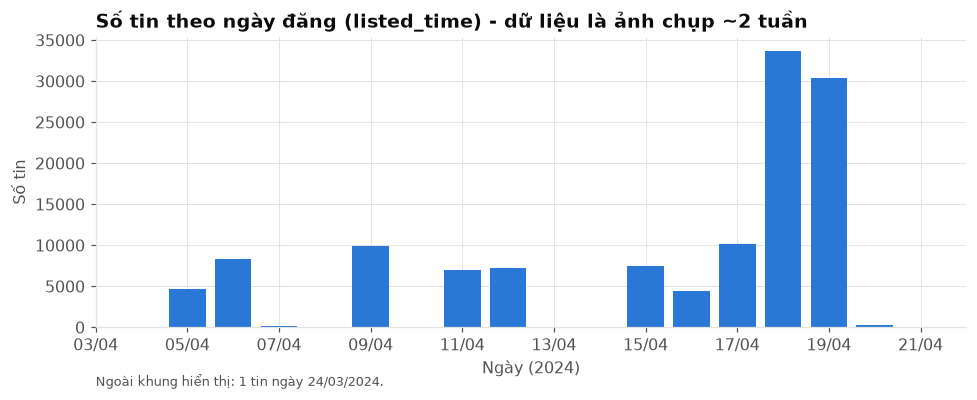

In [6]:
t = pd.to_datetime(raw['listed_time'], unit='ms')
o = pd.to_datetime(raw['original_listed_time'], unit='ms')
print('listed_time:          ', t.min(), '→', t.max())
print('original_listed_time: ', o.min(), '→', o.max())
print(f'Tin có listed_time trong 05-20/04/2024: {t.between("2024-04-05", "2024-04-21").mean():.4%}')

per_day = t.dt.normalize().value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(per_day.index, per_day.values, width=0.8, color=SERIES[0])
ax.set_title('Số tin theo ngày đăng (listed_time) - dữ liệu là ảnh chụp ~2 tuần')
ax.set_xlabel('Ngày (2024)'); ax.set_ylabel('Số tin')
ax.set_xlim(pd.Timestamp('2024-04-03'), pd.Timestamp('2024-04-22'))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d/%m'))
note(ax, 'Ngoài khung hiển thị: 1 tin ngày 24/03/2024.')
plt.tight_layout(); plt.show()

Số tin dồn vào 18-19/04 (~64,000 tin) và có những ngày gần như không có tin (08/04, 10/04, 13-14/04) - đây là **lịch chạy của bộ cào**, không phải nhịp tuyển dụng thật. Vì vậy nhóm **không** đặt câu hỏi về xu hướng theo thời gian; tiêu chí D2 (reshaping) sẽ được đáp ứng bằng pivot/melt thay vì chuỗi thời gian.

### 2.2 Cột số

Các cột số có ý nghĩa: `views`, `applies`, `min/med/max_salary`, `normalized_salary`. (`job_id`, `company_id`, `zip_code`, `fips` là mã định danh, không phân tích như số.)

In [7]:
num_cols = ['views', 'applies', 'min_salary', 'med_salary', 'max_salary', 'normalized_salary']
desc = raw[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc['skew'] = raw[num_cols].skew()
desc

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew
views,"122,160.000",14.618,85.904,1.000,1.000,3.000,4.000,8.000,177.000,"9,975.000",53.725
applies,"23,320.000",10.592,29.047,1.000,1.000,1.000,3.000,8.000,133.810,967.000,9.436
min_salary,"29,793.000","64,910.847","495,973.794",1.000,13.920,37.000,"60,000.000","100,000.000","247,696.800","85,000,000.000",168.586
med_salary,"6,280.000","22,015.620","52,255.874",0.000,12.000,18.940,25.500,"2,510.500","225,000.000","750,000.000",4.498
max_salary,"29,793.000","91,939.423","701,110.139",1.000,16.000,48.280,"80,000.000","140,000.000","352,148.000","120,000,000.000",167.931
normalized_salary,"36,073.000","205,327.037","5,097,626.762",0.000,130.000,"52,000.000","81,500.000","125,000.000","300,808.000","535,600,000.000",65.299


Nhận xét nhanh: mọi cột đều **lệch phải rất mạnh** (skew ≫ 1, mean ≫ median). `normalized_salary` có max **535.6 triệu USD/năm** và min **0** - rõ ràng có giá trị không hợp lệ. `min_salary`, `max_salary` lẫn nhiều đơn vị (giờ, tháng, năm) nên không thể so sánh trực tiếp; phải xem theo `pay_period`.

                count        mean         std       min        1%         50%         99%             max
pay_period                                                                                               
HOURLY     14,741.000     158.954   3,811.370     7.000    13.000      25.250     100.000     257,500.000
WEEKLY        177.000   2,145.383     411.196   977.000 1,134.800   2,099.000   3,318.103       4,049.000
BIWEEKLY        9.000  48,025.444  34,949.850 2,057.000 2,063.160  60,492.500  80,478.720      80,644.000
MONTHLY       518.000   5,340.226   6,182.533    35.000   500.000   4,469.500  14,896.455     100,000.000
YEARLY     20,628.000 119,684.740 715,897.775     0.000    44.405 102,000.000 337,500.000 102,500,000.000


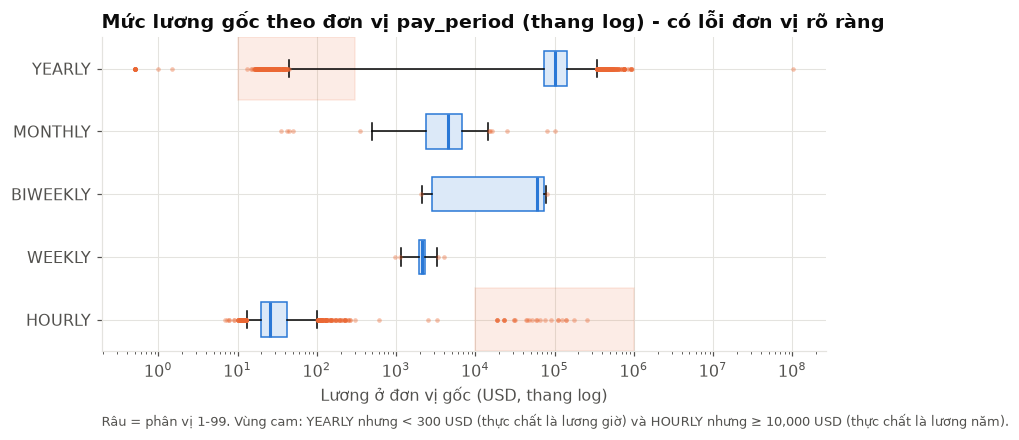

In [8]:
sal = raw[raw['pay_period'].notna()].copy()
sal['mid_raw'] = np.where(sal['med_salary'].notna(), sal['med_salary'], (sal['min_salary'] + sal['max_salary']) / 2)
order = ['HOURLY', 'WEEKLY', 'BIWEEKLY', 'MONTHLY', 'YEARLY']
print(sal.groupby('pay_period')['mid_raw'].describe(percentiles=[.01, .5, .99]).loc[order])

fig, ax = plt.subplots(figsize=(9, 4.2))
data = [sal.loc[sal['pay_period'] == p, 'mid_raw'].clip(lower=0.5) for p in order]
bp = ax.boxplot(data, orientation='horizontal', tick_labels=order, whis=(1, 99), widths=0.55, patch_artist=True,
                flierprops=dict(marker='o', markersize=3, alpha=0.4, markerfacecolor=SERIES[1], markeredgewidth=0))
for b in bp['boxes']:
    b.set(facecolor='#dce9f8', edgecolor=SERIES[0])
for m in bp['medians']:
    m.set(color=SERIES[0], linewidth=2)
ax.set_xscale('log')
ax.axvspan(10, 300, ymin=0.8, ymax=1.0, color=SERIES[1], alpha=0.12)
ax.axvspan(10_000, 1e6, ymin=0.0, ymax=0.2, color=SERIES[1], alpha=0.12)
ax.set_title('Mức lương gốc theo đơn vị pay_period (thang log) - có lỗi đơn vị rõ ràng')
ax.set_xlabel('Lương ở đơn vị gốc (USD, thang log)')
note(ax, 'Râu = phân vị 1-99. Vùng cam: YEARLY nhưng < 300 USD (thực chất là lương giờ) và HOURLY nhưng ≥ 10,000 USD (thực chất là lương năm).', y=-0.2)
plt.tight_layout(); plt.show()

In [9]:
yearly_small = sal[(sal['pay_period'] == 'YEARLY') & sal['mid_raw'].between(10, 300, inclusive='left')]
hourly_big = sal[(sal['pay_period'] == 'HOURLY') & (sal['mid_raw'] >= 10_000)]
print(f'YEARLY nhưng $10-300  : {len(yearly_small):,} tin (giống lương giờ)')
print(f'HOURLY nhưng ≥ $10,000: {len(hourly_big):,} tin (giống lương năm)')
print(f'Tin không phải USD    : {(sal["currency"] != "USD").sum():,}')
cols = ['title', 'pay_period', 'min_salary', 'max_salary', 'med_salary', 'normalized_salary']
pd.concat([yearly_small[cols].sample(4, random_state=1), hourly_big[cols].sample(4, random_state=1)])

YEARLY nhưng $10-300  : 375 tin (giống lương giờ)
HOURLY nhưng ≥ $10,000: 27 tin (giống lương năm)
Tin không phải USD    : 15


,title,pay_period,min_salary,max_salary,med_salary,normalized_salary
25754,Network Engineer - Azure Government,YEARLY,55.000,60.000,NaN,57.500
92237,Mainframe CICS Engineer,YEARLY,90.000,105.000,NaN,97.500
72504,Area Sales Manager - Sacramento,YEARLY,36.000,45.000,NaN,40.500
69609,Senior Office Administrator,YEARLY,21.000,22.000,NaN,21.500
98507,Summer Intern,HOURLY,"15,600.000","21,593.000",NaN,"38,680,720.000"
92706,Ark Encounter Admissions Specialist Full Time-...,HOURLY,"26,520.000","34,840.000",NaN,"63,814,400.000"
98508,Summer Intern,HOURLY,"15,600.000","21,593.000",NaN,"38,680,720.000"
19869,Full Time Field Service Technician – Wilmingto...,HOURLY,"45,000.000","50,000.000",NaN,"98,800,000.000"


Các ví dụ trên cho thấy lỗi **nhập sai đơn vị** chứ không phải lương thật: một vị trí "YEARLY" trả $25 rõ ràng là $25/giờ; "HOURLY" $120,000 là lương năm. Nếu dùng nguyên `normalized_salary`, các tin "HOURLY $120,000" sẽ thành **$250 triệu/năm** - đây chính là các max vô lý ở bảng thống kê.

**Quy tắc làm sạch lương** (cài trong `src/data.py::repair_and_annualize_salary`):
1. Điểm giữa = `med_salary` nếu có, ngược lại `(min_salary + max_salary)/2` (đã kiểm tra: khớp 100% với cách tác giả tính `normalized_salary`).
2. **Sửa đơn vị:** YEARLY với điểm giữa trong [$10, $300) → HOURLY; HOURLY với điểm giữa ≥ $10,000 → YEARLY.
3. Quy về lương năm: HOURLY × 2080 giờ, WEEKLY × 52, BIWEEKLY × 26, MONTHLY × 12.
4. Chỉ giữ USD, và lương năm trong **[$15,080; $1,000,000]** (cận dưới = lương tối thiểu liên bang $7.25 × 2080 giờ). Ngoài khoảng này coi là không hợp lệ.

Ở notebook 02, mọi kết luận về lương đều được kiểm tra lại với quy tắc khác (không sửa đơn vị, chỉ lấy YEARLY, khoảng [$20k; $500k]).

In [10]:
fixed = repair_and_annualize_salary(raw)
print(fixed['salary_status'].value_counts().to_string())
ann = fixed['annual_salary'].dropna()
log_s = np.log(ann)
q1, q3 = log_s.quantile([.25, .75]); iqr = q3 - q1
lo_f, hi_f = np.exp(q1 - 1.5 * iqr), np.exp(q3 + 1.5 * iqr)
z = (log_s - log_s.mean()) / log_s.std()
print(f'\nLương năm hợp lệ: n = {len(ann):,}, median = ${ann.median():,.0f}, IQR = ${ann.quantile(.25):,.0f}-${ann.quantile(.75):,.0f}')
print(f'Rào IQR trên log-lương: ${lo_f:,.0f} - ${hi_f:,.0f} → {((ann < lo_f) | (ann > hi_f)).sum():,} giá trị ngoại lai')
print(f'|z| > 3 trên log-lương: {(z.abs() > 3).sum():,} giá trị')

salary_status
not_disclosed    87776
valid            35559
repaired           402
out_of_range        97
non_usd             15

Lương năm hợp lệ: n = 35,961, median = $82,500, IQR = $52,228-$125,000
Rào IQR trên log-lương: $14,106 - $462,828 → 84 giá trị ngoại lai
|z| > 3 trên log-lương: 102 giá trị


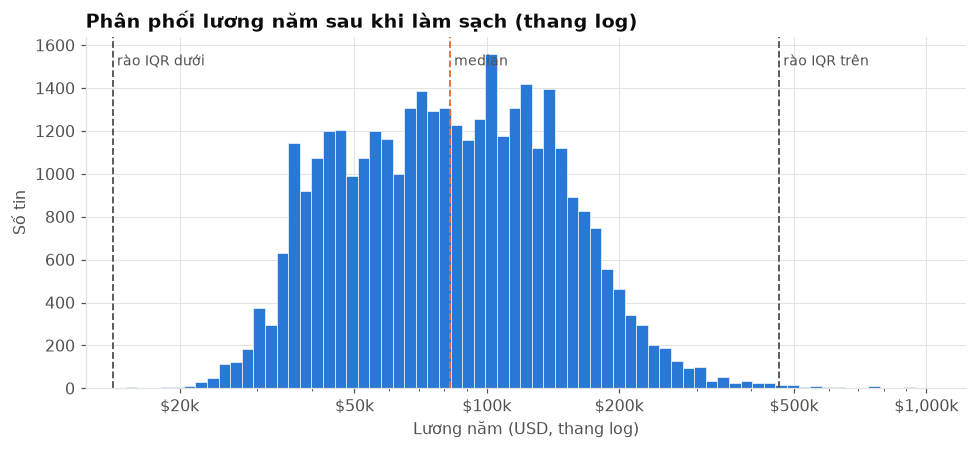

,title,formatted_experience_level,annual_salary
30476,Modernization Software Dev,Associate,"960,000.000"
116367,Quantitative Researcher,Mid-Senior level,"950,000.000"
4781,Partner (& Groups w/ Portable Business for Top...,NaN,"925,000.000"
4908,Partner (& Groups w/ Portable Business for Top...,NaN,"925,000.000"
4735,Partner (& Groups w/ Portable Business for Top...,NaN,"925,000.000"
91967,"Corporate, Litigation, Intellectual Property ,...",NaN,"925,000.000"
113069,Head of Front Office Technology,NaN,"875,000.000"
117057,Quantitative Researcher,Mid-Senior level,"825,000.000"


In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.logspace(np.log10(SALARY_MIN), np.log10(SALARY_MAX), 70)
ax.hist(ann, bins=bins, color=SERIES[0], edgecolor='white', linewidth=0.4)
ax.set_xscale('log')
for v, lab in [(lo_f, 'rào IQR dưới'), (hi_f, 'rào IQR trên'), (ann.median(), 'median')]:
    ax.axvline(v, color=TEXT_2 if lab != 'median' else SERIES[1], linestyle='--', linewidth=1.2)
    ax.text(v, ax.get_ylim()[1] * 0.95, ' ' + lab, color=TEXT_2, fontsize=9, va='top')
ax.set_xticks([20_000, 50_000, 100_000, 200_000, 500_000, 1_000_000])
ax.xaxis.set_major_formatter(usd); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_title('Phân phối lương năm sau khi làm sạch (thang log)')
ax.set_xlabel('Lương năm (USD, thang log)'); ax.set_ylabel('Số tin')
plt.tight_layout(); plt.show()

hi = fixed.loc[fixed['annual_salary'] > hi_f].join(raw[['title', 'formatted_experience_level']])
hi[['title', 'formatted_experience_level', 'annual_salary']].sort_values('annual_salary', ascending=False).head(8)

Sau khi làm sạch, log-lương có dạng gần chuẩn, hơi **hai đỉnh**: một đỉnh quanh $35-45k (việc trả theo giờ: bán lẻ, chăm sóc, hành chính) và một đỉnh quanh $100-130k (việc trả theo năm, chuyên môn). Các giá trị vượt rào IQR trên phần lớn là **thật** (bác sĩ, giám đốc, Executive…) nên **giữ lại**; cận $1 triệu đã loại các lỗi rõ ràng. Vì phân phối lệch, các phân tích lương dùng **median** và **log-lương** thay cho mean.

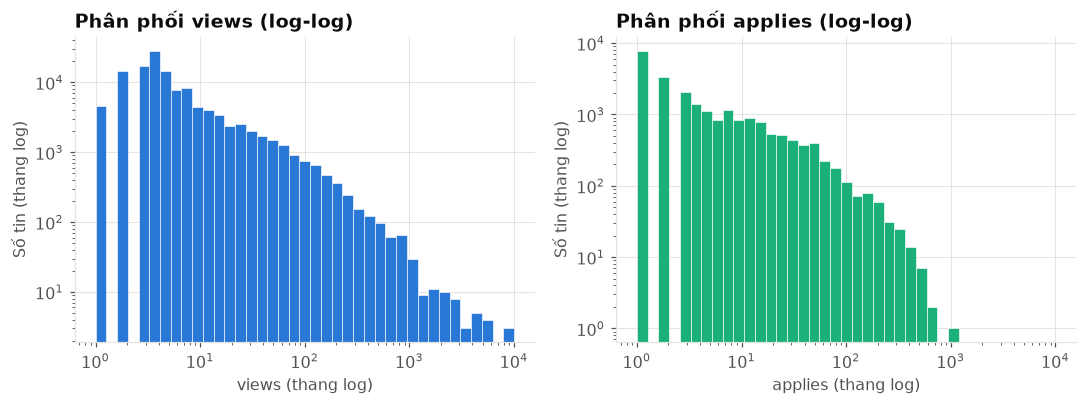

views:   median=4, p99=177, max=9,975, min=1
applies: median=3, p99=134, max=967, min=1, số giá trị 0 = 0
Tin có applies > views: 0


In [12]:
v = raw['views'].dropna(); a = raw['applies'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, s, name, c in [(axes[0], v, 'views', SERIES[0]), (axes[1], a, 'applies', SERIES[2])]:
    ax.hist(s, bins=np.logspace(0, 4, 40), color=c, edgecolor='white', linewidth=0.4)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(f'Phân phối {name} (log-log)'); ax.set_xlabel(f'{name} (thang log)'); ax.set_ylabel('Số tin (thang log)')
plt.tight_layout(); plt.show()
print(f'views:   median={v.median():.0f}, p99={v.quantile(.99):.0f}, max={v.max():,.0f}, min={v.min():.0f}')
print(f'applies: median={a.median():.0f}, p99={a.quantile(.99):.0f}, max={a.max():,.0f}, min={a.min():.0f}, số giá trị 0 = {(a == 0).sum()}')
print(f'Tin có applies > views: {(raw["applies"] > raw["views"]).sum()}')

`views` và `applies` có **đuôi dài kiểu luật luỹ thừa** (gần như đường thẳng trên thang log-log): đa số tin chỉ vài lượt xem, vài tin có hàng nghìn. Giá trị lớn là thật (tin hot), không phải lỗi - không có trường hợp applies > views. Điều đáng chú ý: **`applies` không bao giờ bằng 0** (min = 1) dù rất nhiều tin ít người xem → gợi ý rằng NaN trong `applies` thực chất là 0 lượt (kiểm tra ở mục 2.4).

### 2.3 Cột phân loại

In [13]:
cat_cols = ['formatted_experience_level', 'formatted_work_type', 'application_type', 'pay_period', 'currency', 'remote_allowed']
for c in cat_cols:
    vc = raw[c].value_counts(dropna=False)
    print(f'\n{c}: {raw[c].nunique()} giá trị khác nhau')
    print((vc / len(raw)).map('{:.1%}'.format).to_string())


formatted_experience_level: 6 giá trị khác nhau
formatted_experience_level
Mid-Senior level    33.5%
Entry level         29.6%
NaN                 23.7%
Associate            7.9%
Director             3.0%
Internship           1.2%
Executive            1.0%

formatted_work_type: 7 giá trị khác nhau
formatted_work_type
Full-time     79.8%
Contract       9.8%
Part-time      7.8%
Temporary      1.0%
Internship     0.8%
Volunteer      0.5%
Other          0.4%

application_type: 4 giá trị khác nhau
application_type
OffsiteApply          68.3%
ComplexOnsiteApply    25.1%
SimpleOnsiteApply      6.6%
UnknownApply           0.0%

pay_period: 5 giá trị khác nhau
pay_period
NaN         70.9%
YEARLY      16.7%
HOURLY      11.9%
MONTHLY      0.4%
WEEKLY       0.1%
BIWEEKLY     0.0%

currency: 6 giá trị khác nhau
currency
NaN    70.9%
USD    29.1%
EUR     0.0%
CAD     0.0%
BBD     0.0%
AUD     0.0%
GBP     0.0%

remote_allowed: 1 giá trị khác nhau
remote_allowed
NaN      87.7%
1.000    12.3%


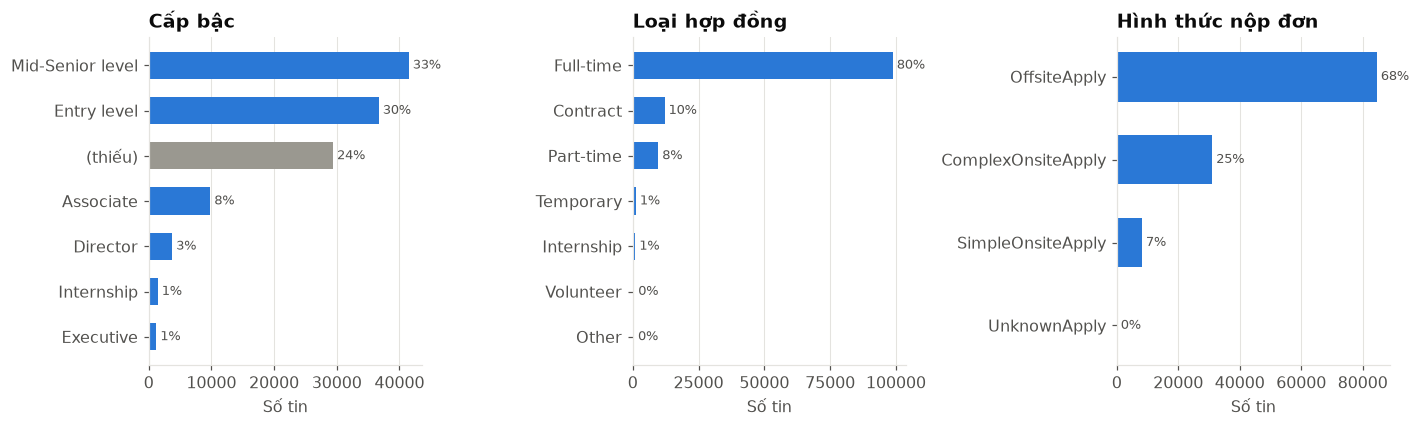

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
specs = [('formatted_experience_level', 'Cấp bậc'), ('formatted_work_type', 'Loại hợp đồng'), ('application_type', 'Hình thức nộp đơn')]
for ax, (c, title) in zip(axes, specs):
    vc = raw[c].fillna('(thiếu)').value_counts().sort_values()
    colors = [NEUTRAL if i == '(thiếu)' else SERIES[0] for i in vc.index]
    ax.barh(vc.index, vc.values, color=colors, height=0.6)
    ax.set_title(title); ax.set_xlabel('Số tin')
    for y, val in enumerate(vc.values):
        ax.text(val, y, f' {val/len(raw):.0%}', va='center', fontsize=8.5, color=TEXT_2)
    ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

- **Mất cân bằng:** 80% là Full-time; 68% nộp đơn ngoài LinkedIn (OffsiteApply). Executive/Internship/Volunteer rất hiếm (< 1.2% mỗi loại) - khi phân tích theo cấp bậc nhóm sẽ tập trung vào Entry → Associate → Mid-Senior → Director.
- **Thiếu cấp bậc 23.7%** → giữ như một nhóm riêng `Unknown` thay vì xoá (xoá sẽ mất ¼ dữ liệu và thiên lệch nếu thiếu không ngẫu nhiên).
- `remote_allowed` chỉ có giá trị 1 hoặc trống → trống nghĩa là *không ghi nhận remote* → mã hoá 0.
- `currency`: 15 tin không phải USD (EUR, CAD, …) → loại khỏi phân tích lương.
- `UnknownApply` chỉ có 1 tin.

In [15]:
# Nhãn không nhất quán: tiêu đề và địa điểm là text tự do
titles = raw['title'].str.strip()
print(f'Tiêu đề khác nhau: {titles.nunique():,} | sau khi lower(): {titles.str.lower().nunique():,}')
print(titles.str.lower().value_counts().head(8).to_string())

loc = raw['location']
pattern = np.select([loc.eq('United States'), loc.str.contains(r',\s*[A-Z]{2}$'),
                     loc.str.contains('United States'), loc.str.contains('Area|Metro|Greater|Region')],
                    ['"United States" (toàn quốc)', '"City, ST"', '"<Bang>, United States"', 'Vùng đô thị (metro)'], 'Khác')
print('\nDạng ghi location:')
print(pd.Series(pattern).value_counts().to_string())

Tiêu đề khác nhau: 72,106 | sau khi lower(): 71,580
title
sales manager                      673
customer service representative    482
project manager                    360
assistant store manager            320
administrative assistant           261
senior accountant                  244
salesperson                        241
executive assistant                232

Dạng ghi location:
"City, ST"                     105090
"United States" (toàn quốc)      8125
Vùng đô thị (metro)              6013
"<Bang>, United States"          4570
Khác                               51


In [16]:
state = parse_state(raw['location'])
print(f'Suy ra được bang: {state.notna().mean():.1%} | "United States": {(raw["location"] == "United States").mean():.1%} | không xác định: {(state.isna() & (raw["location"] != "United States")).mean():.1%}')
print('Các location không suy ra được bang (top 8):')
print(raw.loc[state.isna() & (raw['location'] != 'United States'), 'location'].value_counts().head(8).to_string())

Suy ra được bang: 92.5% | "United States": 6.6% | không xác định: 0.9%
Các location không suy ra được bang (top 8):
location
Washington DC-Baltimore Area                  269
Kansas City Metropolitan Area                  65
Gainesville Metropolitan Area                  52
NAMER                                          34
Grand Rapids Metropolitan Area                 28
Buffalo-Niagara Falls Area                     25
Greensboro--Winston-Salem--High Point Area     23
Knoxville Metropolitan Area                    20


- **Tiêu đề:** 72,106 tiêu đề khác nhau; chuẩn hoá chữ thường chỉ gộp thêm ~500 ("Sales Manager" vs "sales manager") - đây là text tự do, không dùng như biến phân loại trực tiếp (notebook 03 dùng TF-IDF).
- **Địa điểm ghi theo 4 kiểu khác nhau** (City, ST / tên bang / vùng metro / "United States"). Nhóm viết hàm `parse_state` suy ra mã bang: đọc ", XX", tên metro đã biết, rồi tên bang đầy đủ. Kết quả: **92.5% tin có bang**, 6.6% là tuyển toàn quốc ("United States", gần như luôn là remote), 0.9% không xác định (chủ yếu vùng metro trải nhiều bang như *Washington DC-Baltimore*, cố ý không gán để tránh sai).
- **Gom nhóm hiếm:** bảng ngành có 422 ngành → khi đưa vào mô hình chỉ giữ ngành có ≥ 20 tin, còn lại gộp "infrequent".

job_skills: 213,768 dòng cho 126,807 tin | số nhóm chức năng/tin: {1: 55149, 2: 56355, 3: 15303}
job_industries: 164,808 dòng cho 127,125 tin, 422 ngành; 100 dòng có industry_id không có tên trong mapping


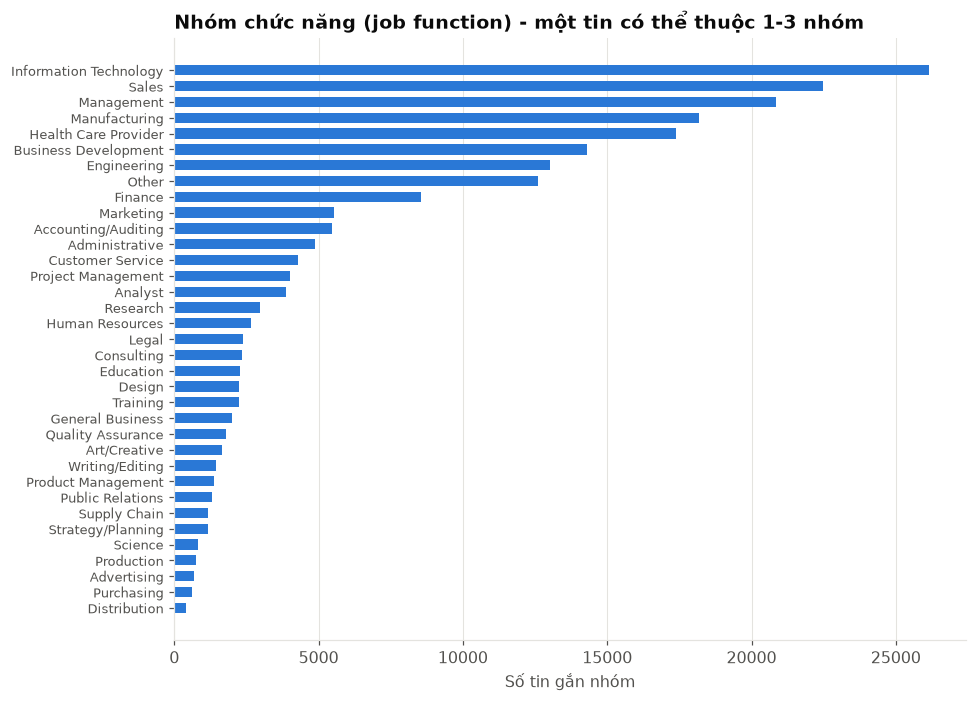

In [17]:
jf = load_job_functions(); ji = load_job_industries()
print(f'job_skills: {len(jf):,} dòng cho {jf.job_id.nunique():,} tin | số nhóm chức năng/tin: ' +
      jf.groupby('job_id').size().value_counts().sort_index().to_dict().__repr__())
print(f'job_industries: {len(ji):,} dòng cho {ji.job_id.nunique():,} tin, {ji.industry_id.nunique()} ngành; '
      f'{ji.industry_name.isna().sum()} dòng có industry_id không có tên trong mapping')
top_f = jf['skill_name'].value_counts()
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top_f.index[::-1], top_f.values[::-1], color=SERIES[0], height=0.65)
ax.set_title('Nhóm chức năng (job function) - một tin có thể thuộc 1-3 nhóm')
ax.set_xlabel('Số tin gắn nhóm'); ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', labelsize=8.5)
plt.tight_layout(); plt.show()

### 2.4 Dữ liệu thiếu

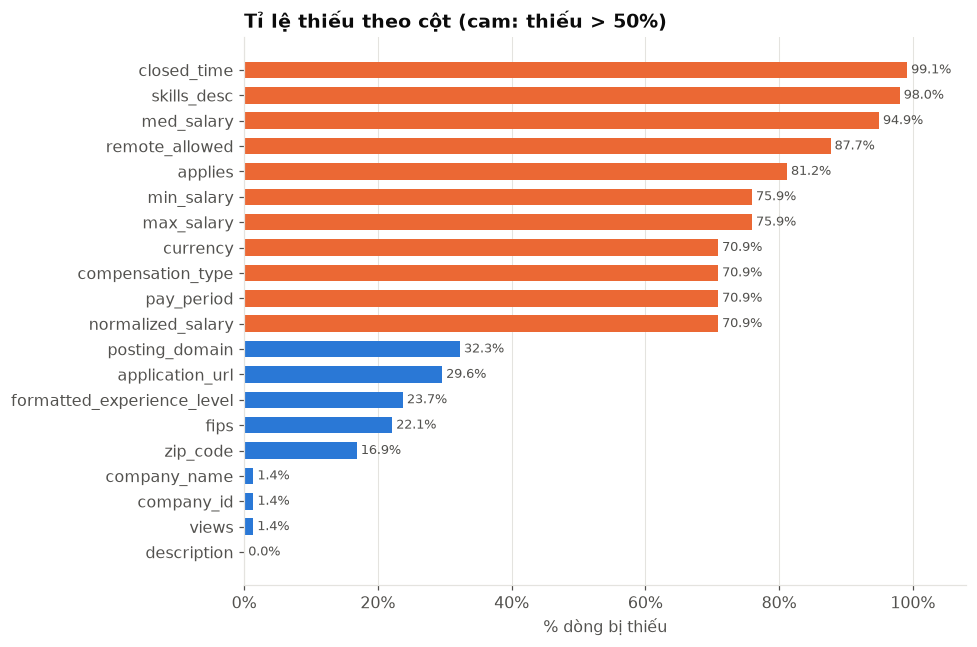

In [18]:
miss = raw.isna().mean().sort_values()
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(9, 6))
colors = [SERIES[1] if m > 0.5 else SERIES[0] for m in miss.values]
ax.barh(miss.index, miss.values, color=colors, height=0.65)
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 1.08)
for y, m in enumerate(miss.values):
    ax.text(m, y, f' {m:.1%}', va='center', fontsize=8.5, color=TEXT_2)
ax.set_title('Tỉ lệ thiếu theo cột (cam: thiếu > 50%)'); ax.set_xlabel('% dòng bị thiếu')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

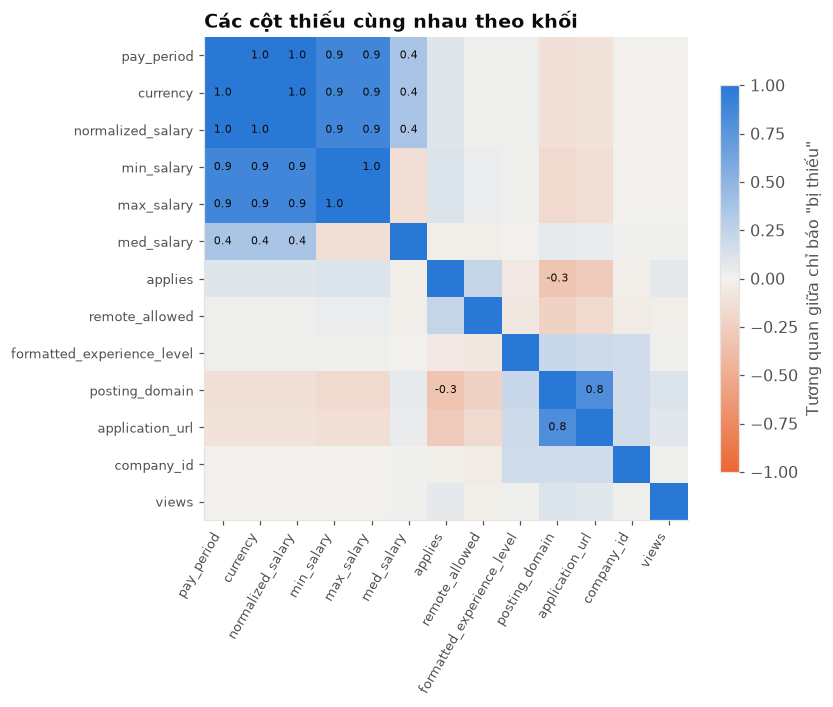

pay_period, currency, normalized_salary thiếu đồng thời: True
Tin có lương: min/max xuất hiện cùng nhau và loại trừ med_salary: True


In [19]:
# Thiếu có theo mẫu không? Tương quan giữa các chỉ báo thiếu
cols = ['pay_period', 'currency', 'normalized_salary', 'min_salary', 'max_salary', 'med_salary',
        'applies', 'remote_allowed', 'formatted_experience_level', 'posting_domain', 'application_url', 'company_id', 'views']
M = raw[cols].isna().astype(int).corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(M, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=60, ha='right', fontsize=8.5)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8.5)
for i in range(len(cols)):
    for j in range(len(cols)):
        if abs(M.iloc[i, j]) >= 0.3 and i != j:
            ax.text(j, i, f'{M.iloc[i, j]:.1f}', ha='center', va='center', fontsize=7.5)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='Tương quan giữa chỉ báo "bị thiếu"')
ax.set_title('Các cột thiếu cùng nhau theo khối')
plt.tight_layout(); plt.show()

print('pay_period, currency, normalized_salary thiếu đồng thời:',
      (raw[['pay_period', 'currency', 'normalized_salary']].isna().nunique(axis=1) == 1).all())
print('Tin có lương: min/max xuất hiện cùng nhau và loại trừ med_salary:',
      ((raw['min_salary'].notna() == raw['max_salary'].notna()) & ~(raw['min_salary'].notna() & raw['med_salary'].notna())).all())

In [20]:
# applies thiếu có phải là 0 lượt?
chk = raw[raw['views'].notna()].assign(applies_missing=lambda d: d['applies'].isna())
print(chk.groupby('applies_missing')['views'].describe()[['count', '25%', '50%', '75%']])
print(f"\nTỉ lệ thiếu applies theo hình thức nộp đơn:\n{raw.groupby('application_type')['applies'].apply(lambda s: s.isna().mean()).map('{:.1%}'.format)}")

# Có lương hay không phụ thuộc vào bang?
disc = raw.assign(state=state, disclosed=raw['pay_period'].notna()).groupby('state')['disclosed'].agg(['mean', 'size'])
disc = disc[disc['size'] >= 500].sort_values('mean', ascending=False)
print('\nTỉ lệ tin CÓ ghi lương - 6 bang cao nhất và 4 thấp nhất (bang ≥ 500 tin):')
print(pd.concat([disc.head(6), disc.tail(4)]).assign(mean=lambda d: d['mean'].map('{:.1%}'.format)).to_string())

                     count    25%    50%    75%
applies_missing                                
False           23,319.000 11.000 23.000 49.000
True            98,841.000  3.000  4.000  5.000

Tỉ lệ thiếu applies theo hình thức nộp đơn:
application_type
ComplexOnsiteApply    62.5%
OffsiteApply          88.5%
SimpleOnsiteApply     76.2%
UnknownApply           0.0%
Name: applies, dtype: str

Tỉ lệ tin CÓ ghi lương - 6 bang cao nhất và 4 thấp nhất (bang ≥ 500 tin):
        mean   size
state              
CA     50.0%  12894
NY     50.0%   7611
WA     49.5%   2886
CO     49.2%   2516
OR     32.9%   1296
DC     31.1%   1036
NM     18.6%    511
SC     17.5%   1684
NC     17.2%   5290
LA      9.7%   1128


**Mẫu của dữ liệu thiếu và cách xử lý:**

| Cột | % thiếu | Vì sao thiếu | Xử lý |
|---|---|---|---|
| `pay_period`, `currency`, `normalized_salary`, `compensation_type` | 70.9% | **Thiếu có cấu trúc:** nhà tuyển dụng không ghi lương - 4 cột thiếu cùng lúc 100% | Không impute. Tạo cờ `salary_disclosed`; phân tích lương chỉ trên tin có lương. Việc *có ghi lương hay không* **phụ thuộc mạnh vào bang** (CA/NY/WA/CO ≈ 49-50% so với ≤ 33% ở mọi bang khác) → **MNAR/MAR**, là điểm xuất phát của Q1 |
| `min_salary`/`max_salary` vs `med_salary` | 75.9% / 94.9% | Tin ghi *khoảng* (min-max) **hoặc** *một con số* (med) - không bao giờ cả hai | Gộp thành điểm giữa |
| `applies` | 81.2% | Không bao giờ có giá trị 0 và tin thiếu `applies` có median views = 4 (so với 23) → **NaN ≈ 0 lượt ứng tuyển** | Điền 0 (`applies_filled`); robustness ở Q5: loại thay vì điền |
| `remote_allowed` | 87.7% | Chỉ ghi khi có remote | NaN → 0 |
| `formatted_experience_level` | 23.7% | Nhà tuyển dụng không chọn cấp bậc | Nhóm riêng `Unknown` |
| `posting_domain`, `application_url` | 30-32% | Chỉ có khi nộp ngoài LinkedIn (cấu trúc) | Không dùng |
| `company_id`, `company_name`, `views` | 1.4% | Tin của công ty không có trang LinkedIn | Giữ; bỏ qua ở phân tích cần thông tin công ty |
| `skills_desc`, `closed_time` | 98-99% | Gần như không thu thập | Bỏ cột |

### 2.5 Quan hệ giữa các biến

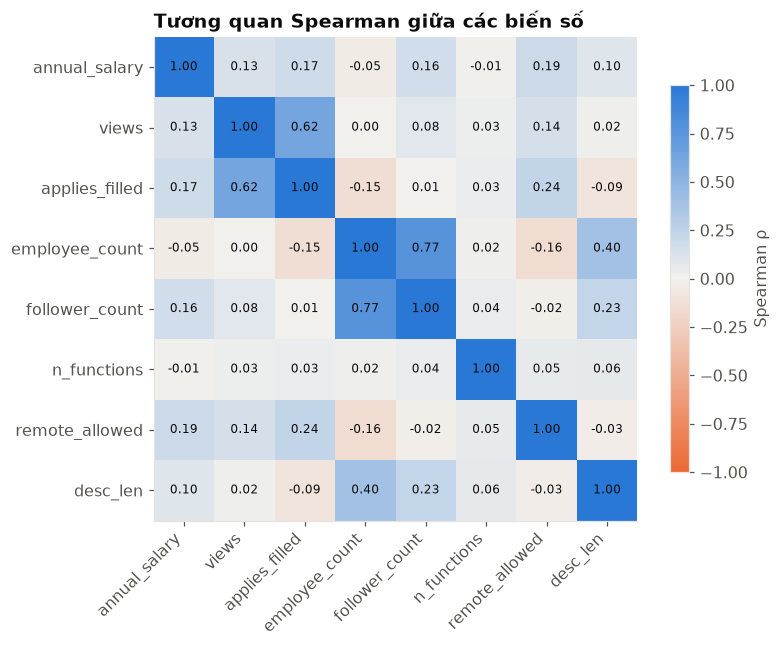

In [21]:
log = []
df = build_analytic_table(log=log)   # bảng đã làm sạch + ghép (chi tiết ở mục 2.7)
df['desc_len'] = raw['description'].str.len().values
num = df[['annual_salary', 'views', 'applies_filled', 'employee_count', 'follower_count', 'n_functions', 'remote_allowed', 'desc_len']]
S = num.corr(method='spearman')
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(S, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(S))); ax.set_xticklabels(S.columns, rotation=45, ha='right')
ax.set_yticks(range(len(S))); ax.set_yticklabels(S.columns)
for i in range(len(S)):
    for j in range(len(S)):
        ax.text(j, i, f'{S.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='Spearman ρ')
ax.set_title('Tương quan Spearman giữa các biến số')
plt.tight_layout(); plt.show()

Dùng **Spearman** vì các biến lệch mạnh và có đuôi dài. Quan hệ đáng kể nhất là `views`-`applies` (ρ = 0.62 sau khi điền 0; 0.82 nếu chỉ xét tin có applies) - hiển nhiên. `employee_count`-`follower_count` tương quan mạnh (ρ = 0.77). **Lương gần như không tương quan với quy mô công ty** (ρ = −0.05) - trái với trực giác "công ty lớn trả cao hơn", được kiểm tra kỹ ở Q4. Lương tương quan dương nhưng yếu với `remote_allowed` (ρ = 0.19). Công ty lớn ít cho remote hơn (ρ = −0.16).

                      median               size      
remote_allowed             0           1      0     1
experience_level                                     
Associate         72,800.000  80,000.000   3402   484
Director         164,660.000 177,400.000   1026   241
Entry level       51,524.500  77,500.000   8502   594
Executive        180,000.000 218,400.000    309    73
Internship        47,840.000  46,800.000    345    32
Mid-Senior level 104,243.500 125,000.000  10641  2242


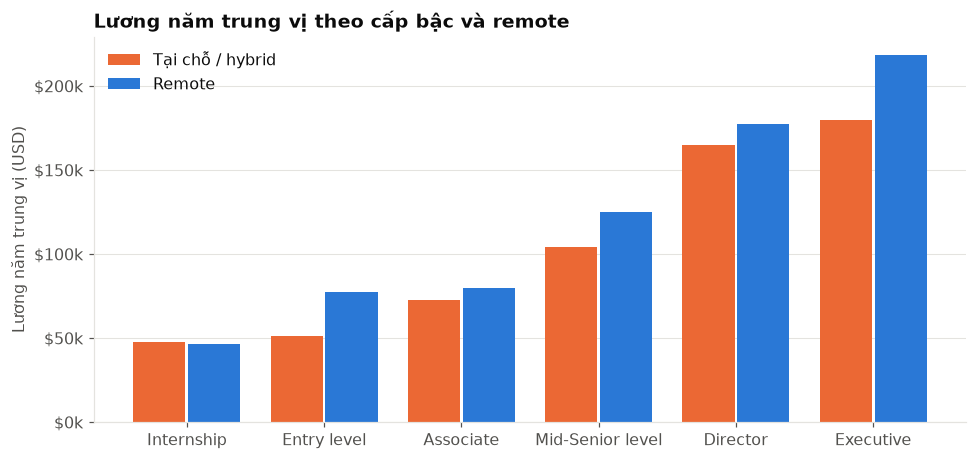

In [22]:
lvl_order = ['Internship', 'Entry level', 'Associate', 'Mid-Senior level', 'Director', 'Executive']
g = (df[df['annual_salary'].notna() & df['experience_level'].isin(lvl_order)]
       .groupby(['experience_level', 'remote_allowed'])['annual_salary'].agg(['median', 'size']).unstack())
print(g)
med = g['median'].loc[lvl_order]
x = np.arange(len(lvl_order)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.bar(x - w/2 - 0.01, med[0], width=w, color=SERIES[1], label='Tại chỗ / hybrid')
ax.bar(x + w/2 + 0.01, med[1], width=w, color=SERIES[0], label='Remote')
ax.set_xticks(x); ax.set_xticklabels(lvl_order)
ax.yaxis.set_major_formatter(usd)
ax.set_title('Lương năm trung vị theo cấp bậc và remote'); ax.set_ylabel('Lương năm trung vị (USD)')
ax.legend(); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

Lương tăng đều theo cấp bậc (median toàn bộ: Entry $52.5k → Associate $74.9k → Mid-Senior $108.9k → Director $167.5k → Executive $195k). Ở **hầu hết** cấp bậc, tin remote có median cao hơn - nhưng tin remote cũng tập trung ở Mid-Senior và IT hơn, nên chênh lệch thô có thể do *thành phần công việc* (Q2 tách hai hiệu ứng này).

In [23]:
ct = pd.crosstab(df['experience_level'], df['work_type'], normalize='index').loc[lvl_order + ['Unknown']]
(ct * 100).round(1)

work_type,Contract,Full-time,Internship,Other,Part-time,Temporary,Volunteer
experience_level,,,,,,,
Internship,0.400,53.300,34.000,0.400,9.600,2.300,0.000
Entry level,4.700,80.100,0.200,0.500,13.500,1.000,0.000
Associate,14.100,76.900,0.100,0.000,3.200,1.200,4.400
Mid-Senior level,12.400,80.800,0.100,0.300,5.200,1.000,0.100
Director,3.600,93.900,0.100,0.200,1.700,0.400,0.000
Executive,3.800,91.900,0.000,0.600,2.800,0.700,0.200
Unknown,12.600,77.900,1.200,0.500,6.900,0.800,0.300


In [24]:
# Mô tả công việc có chứa con số tiền không? (cảnh báo leakage cho câu hỏi ML)
has_money = raw['description'].str.contains(r'\$\s?\d', regex=True, na=False)
print(pd.crosstab(raw['pay_period'].notna().rename('có lương có cấu trúc'), has_money.rename('mô tả chứa "$<số>"'), normalize='index').round(3))

mô tả chứa "$<số>"    False  True 
có lương có cấu trúc              
False                 0.740  0.260
True                  0.284  0.716


**Phát hiện quan trọng cho câu hỏi ML:** 72% tin *có* lương ghi con số "$…" ngay trong `description` (so với 26% tin không có lương). Nếu dùng mô tả làm đặc trưng để dự đoán lương, mô hình sẽ "đọc đáp án" - **rò rỉ dữ liệu (data leakage)**. Notebook 03 vì vậy chỉ dùng tiêu đề, không dùng mô tả.

### 2.6 Các bảng phụ và kiểm tra khoá ghép

In [25]:
comp = pd.read_csv(RAW_DIR / 'companies' / 'companies.csv')
emp = pd.read_csv(RAW_DIR / 'companies' / 'employee_counts.csv')
cind = pd.read_csv(RAW_DIR / 'companies' / 'company_industries.csv')
ben = pd.read_csv(RAW_DIR / 'jobs' / 'benefits.csv')
checks = pd.DataFrame([
    ('companies.company_id duy nhất', comp['company_id'].is_unique),
    ('employee_counts: số snapshot / công ty (max)', emp.groupby('company_id').size().max()),
    ('employee_counts: % công ty có > 1 snapshot', f"{(emp.groupby('company_id').size() > 1).mean():.1%}"),
    ('company_industries: công ty có > 1 ngành', cind['company_id'].duplicated().sum()),
    ('% company_id của postings tìm thấy trong companies', f"{raw['company_id'].dropna().isin(comp['company_id']).mean():.4%}"),
    ('% tin có trong job_skills', f"{raw['job_id'].isin(jf['job_id']).mean():.2%}"),
    ('% tin có trong job_industries', f"{raw['job_id'].isin(ji['job_id']).mean():.2%}"),
    ('% tin có trong benefits', f"{raw['job_id'].isin(ben['job_id']).mean():.2%}"),
    ('company_size (mã 0-7) thiếu', f"{comp['company_size'].isna().mean():.1%}"),
], columns=['kiểm tra', 'kết quả'])
checks

,kiểm tra,kết quả
0,companies.company_id duy nhất,True
1,employee_counts: số snapshot / công ty (max),13
2,employee_counts: % công ty có > 1 snapshot,23.3%
3,company_industries: công ty có > 1 ngành,10
4,% company_id của postings tìm thấy trong compa...,99.9992%
5,% tin có trong job_skills,98.58%
6,% tin có trong job_industries,98.84%
7,% tin có trong benefits,23.20%
8,company_size (mã 0-7) thiếu,11.3%


- `employee_counts` có **nhiều snapshot theo thời gian** cho cùng một công ty (23% công ty có > 1 lần ghi) → giữ **snapshot mới nhất**.
- 10 công ty có 2 ngành trong `company_industries` → giữ ngành đầu tiên để ghép 1:1.
- Gần như mọi `company_id` của postings đều có trong `companies` (chỉ 1 ID không khớp) → ghép không mất dòng.
- `job_skills` là quan hệ **nhiều-nhiều** (1-3 nhóm/tin): dùng nhóm đầu tiên làm "chức năng chính", và ở Q3 dùng dạng dài (melt) để không bỏ sót.
- `benefits` chỉ có ở 24% tin, 60% phúc lợi là "inferred" (LinkedIn tự suy ra) → không đủ tin cậy để làm câu hỏi chính.

### 2.7 Tiền xử lý chung & lưu dữ liệu

Hàm `build_analytic_table()` trong `src/data.py` thực hiện mọi bước ở trên theo thứ tự: bỏ cột vô ích → đổi kiểu thời gian → mã hoá `remote_allowed`, `experience_level` → suy ra `state` và cờ `transparency_state` → sửa đơn vị & quy đổi lương năm → `applies_filled` → ghép công ty (snapshot nhân viên mới nhất, ngành công ty) → ghép nhóm chức năng chính và ngành chính của tin. **Không xoá dòng nào ở bước chung**: các bộ lọc (vd. chỉ tin có lương) được áp dụng và báo cáo số dòng ngay trong từng câu hỏi. Nhật ký số dòng sau mỗi bước ghép:

In [26]:
pd.DataFrame(log)

,bước,trước,sau,chênh lệch
0,clean_postings (không xoá dòng),123849,123849,0
1,employee_counts: giữ snapshot mới nhất / công ty,35787,24473,-11314
2,company_industries: 1 ngành / công ty,24375,24365,-10
3,companies ⨝ employee_counts ⨝ company_industries,24473,24473,0
4,"postings ⨝ companies (left, m:1)",123849,123849,0
5,⨝ nhóm chức năng chính (job_skills),123849,123849,0
6,⨝ ngành chính của tin (job_industries),123849,123849,0


In [27]:
print(df.shape)
print(df['salary_status'].value_counts().to_string())
print(f"\nTin có lương năm hợp lệ (valid + repaired): {df['annual_salary'].notna().sum():,}")
keep = [c for c in df.columns if c not in ('description', 'desc_len')]
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
df[keep].to_parquet(PROCESSED_DIR / 'postings_clean.parquet', index=False)
print('Đã lưu:', PROCESSED_DIR / 'postings_clean.parquet')

(123849, 46)
salary_status
not_disclosed    87776
valid            35559
repaired           402
out_of_range        97
non_usd             15

Tin có lương năm hợp lệ (valid + repaired): 35,961
Đã lưu: /home/tienbaka/PFDS-Final-Project/data/processed/postings_clean.parquet


### 2.8 Tóm tắt khám phá

**Quan sát chính**
1. Dữ liệu là **ảnh chụp ~2 tuần (05-20/04/2024)** của 123,849 tin ở Mỹ; lịch cào không đều → không phân tích xu hướng thời gian.
2. **Chỉ 29% tin công bố lương**, và tỉ lệ này **gấp ~2 lần ở các bang có luật minh bạch lương** (CA, WA, CO, NY ≈ 50%) so với phần lớn các bang khác.
3. Lương lệch phải mạnh, hai đỉnh (việc theo giờ vs việc theo năm); tăng rõ theo cấp bậc. Tin remote có median cao hơn ~47% - nhưng thành phần công việc khác nhau.
4. `views`/`applies` có đuôi dài; `applies` thiếu thực chất là 0.
5. 72% tin có lương ghi luôn số tiền trong mô tả → nguy cơ leakage cho mô hình.

**Vấn đề chất lượng nghiêm trọng:** lỗi đơn vị lương (402 tin sửa được, 97 tin loại); địa điểm ghi 4 kiểu khác nhau; 10% tin là bản sao đa địa điểm; thiếu dữ liệu có cấu trúc (không ngẫu nhiên) ở lương; employee_counts có nhiều snapshot.

**Kế hoạch tiền xử lý:** như mục 2.7 - sửa & quy đổi lương, suy ra bang, mã hoá thiếu theo ý nghĩa, ghép bảng 1:1 với kiểm tra số dòng; lọc theo từng câu hỏi; robustness với quy tắc làm sạch khác và loại bản trùng.

**Mẫu gợi ý câu hỏi:** chênh lệch công bố lương giữa các bang (→ Q1), chênh lệch lương remote (→ Q2), lương tăng theo cấp bậc khác nhau giữa các nhóm nghề (→ Q3), lương không tăng theo quy mô công ty (→ Q4), tỉ lệ ứng tuyển/lượt xem khác nhau theo đặc điểm tin (→ Q5), 71% tin thiếu lương cần được ước lượng (→ Q6).

## 3. Câu hỏi nghiên cứu (mục 3.3)

Nhóm 3 người → **6 câu hỏi**, mỗi người phụ trách 2 câu, có 1 câu dùng ML (Q6).

| # | Câu hỏi | Người phụ trách | D1 Ghép | D2 Reshape | D3 Biến dẫn xuất | D4 Confounder | D5 Bất định | D6 Robustness |
|---|---|---|:-:|:-:|:-:|:-:|:-:|:-:|
| Q1 | Luật minh bạch lương & tỉ lệ công bố lương | Đinh Võ Thủy Tiên | ✓ | | ✓ | ✓ | ✓ | ✓ |
| Q2 | Mức chênh lương của việc remote | Đinh Võ Thủy Tiên | | | ✓ | ✓ | ✓ | ✓ |
| Q3 | "Bậc thang lương" Entry → Mid-Senior theo nhóm nghề | Huỳnh Huy Hoàng | ✓ | ✓ | ✓ | | ✓ | ✓ |
| Q4 | Công ty lớn có trả cao hơn không? | Huỳnh Huy Hoàng | ✓ | | ✓ | ✓ | ✓ | ✓ |
| Q5 | Yếu tố nào làm người xem nộp đơn nhiều hơn? | Hoàng Hùng Quân | | | ✓ | ✓ | ✓ | ✓ |
| Q6 | **(ML)** Dự đoán lương cho tin không công bố lương | Hoàng Hùng Quân | ✓ | | ✓ | | | |

Mỗi câu non-ML dùng ≥ 4 tiêu chí; cả nhóm phủ **đủ 6/6 tiêu chí**.

**Q1 - Luật minh bạch lương.** *Các bang bắt buộc ghi khoảng lương trong tin tuyển dụng (CA, CO, WA, NY, HI - luật có hiệu lực trước 04/2024) có tỉ lệ tin công bố lương cao hơn bao nhiêu điểm phần trăm so với các bang không có luật, khi so sánh **trong cùng một công ty**, cùng nhóm chức năng và cùng quy mô công ty? Các bang chỉ yêu cầu cung cấp lương "khi ứng viên hỏi" (CT, NV, RI, MD) có khác các bang không có luật không?*
**Động lực:** nhà hoạch định chính sách ở các bang đang cân nhắc luật tương tự (IL, MN, MA… có hiệu lực 2025) muốn biết luật có thực sự thay đổi hành vi nhà tuyển dụng; người tìm việc muốn biết nên tìm tin ở đâu để thấy lương. So sánh trong cùng công ty loại bỏ giải thích "bang đó có nhiều công ty thích công khai sẵn".

**Q2 - Remote premium.** *Tin cho phép làm từ xa có lương công bố cao hơn tin tại chỗ bao nhiêu %, và chênh lệch đó còn lại bao nhiêu sau khi kiểm soát cấp bậc, nhóm chức năng, loại hợp đồng, đơn vị trả lương, bang, quy mô và ngành?*
**Động lực:** người tìm việc cân nhắc đánh đổi giữa remote và lương ("remote có bị trả thấp hơn không?"); nhà tuyển dụng cần biết mức lương cạnh tranh cho vị trí remote. Câu hỏi tách *hiệu ứng remote* khỏi *hiệu ứng thành phần* (remote tập trung ở việc IT, cấp cao).

**Q3 - Bậc thang lương theo nghề.** *Trong mỗi nhóm chức năng, lương trung vị của cấp Mid-Senior gấp bao nhiêu lần cấp Entry (kèm khoảng tin cậy bootstrap)? Nhóm nào có bậc thang dốc nhất/thoải nhất, và thứ hạng này có giữ nguyên khi chỉ xét việc trả lương năm hay khi đổi quy tắc làm sạch không?*
**Động lực:** sinh viên chọn hướng nghề nghiệp không chỉ nhìn lương khởi điểm mà cả *tốc độ tăng lương*; một nghề lương khởi điểm cao nhưng bậc thang thoải có thể kém hấp dẫn về dài hạn.

**Q4 - Quy mô công ty.** *Với công việc tương đương (cùng cấp bậc, chức năng, loại hợp đồng, đơn vị trả lương, bang, remote), công ty có ≥ 10,000 nhân viên trả lương công bố cao hơn công ty nhỏ bao nhiêu %? Kết luận từ số liệu thô có bị đảo chiều khi kiểm soát các yếu tố này không?*
**Động lực:** kinh tế học lao động ghi nhận "firm-size wage premium"; người tìm việc cân nhắc giữa startup và tập đoàn. Số liệu thô của dataset lại cho thấy điều ngược lại → cần kiểm tra nghịch lý kiểu Simpson.

**Q5 - Tỉ lệ ứng tuyển.** *Trong các tin có ≥ 10 lượt xem, những yếu tố nhà tuyển dụng kiểm soát được - cho phép remote, công khai lương - gắn với tỉ lệ ứng tuyển trên lượt xem (applies/views) cao hơn bao nhiêu điểm phần trăm, khi so sánh trong cùng hình thức nộp đơn, cấp bậc và nhóm chức năng? Kết luận có đổi khi thay ngưỡng lượt xem hoặc cách xử lý `applies` bị thiếu không?*
**Động lực:** nhà tuyển dụng muốn tối ưu tin đăng để thu hút ứng viên với chi phí thấp - nên ưu tiên cho remote hay công khai lương?

**Q6 - ML: ước lượng lương.** *Có thể ước lượng lương năm của một tin tuyển dụng từ thông tin có sẵn tại thời điểm đăng tin (tiêu đề, cấp bậc, loại hợp đồng, bang, remote, chức năng, ngành, quy mô công ty) với sai số đủ nhỏ để hữu ích không? Yếu tố nào quyết định mức lương dự đoán?*
**Động lực:** 71% tin không ghi lương. Người tìm việc cần một ước lượng hợp lý trước khi ứng tuyển/đàm phán; nhà tuyển dụng ở bang có luật cần một khoảng lương tham chiếu khi soạn tin. Chi tiết thiết kế (loại leakage, chia theo công ty) ở notebook 03.